<p align="center">
  <span style="color:Navy; font-size:200%; font-weight:bold; vertical-align:middle;">
    Temas Selectos: Python para Ciencias de la Tierra
  </span>
</p>

# <font color="purple"> **Análisis espacial: Rasterio**</font>

---

# **<font color="SeaGreen"> ¿Qué es un ráster? </font>**

Los datos ráster o “gridded” se almacenan como una cuadrícula de valores que se representan en un mapa como píxeles. Cada valor de píxel representa un área en la superficie de la Tierra. Un archivo ráster está compuesto por una cuadrícula regular de celdas, todas del mismo tamaño.

Si has visto y utilizado rásteres antes, probablemente haya sido al observar fotografías o imágenes en herramientas como Google Earth. Sin embargo, los archivos ráster con los que trabajarás son diferentes de las fotografías, ya que están georreferenciados. **Cada píxel representa un área de tierra en el suelo, y esa área está definida por la resolución espacial del ráster.**

* Cada celda se llama píxel.
* Cada píxel representa un área en la superficie terrestre.
* La resolución del ráster indica el área que cada píxel representa en el suelo. Por ejemplo, un ráster con una resolución de 1 metro significa que cada píxel representa un área de 1 m × 1 m en el suelo si su CRS está en metros.
* Un conjunto de datos ráster puede tener atributos asociados. Por ejemplo, en un Modelo Digital de Elevación (DEM), cada celda representa un valor de elevación para esa ubicación en la Tierra.

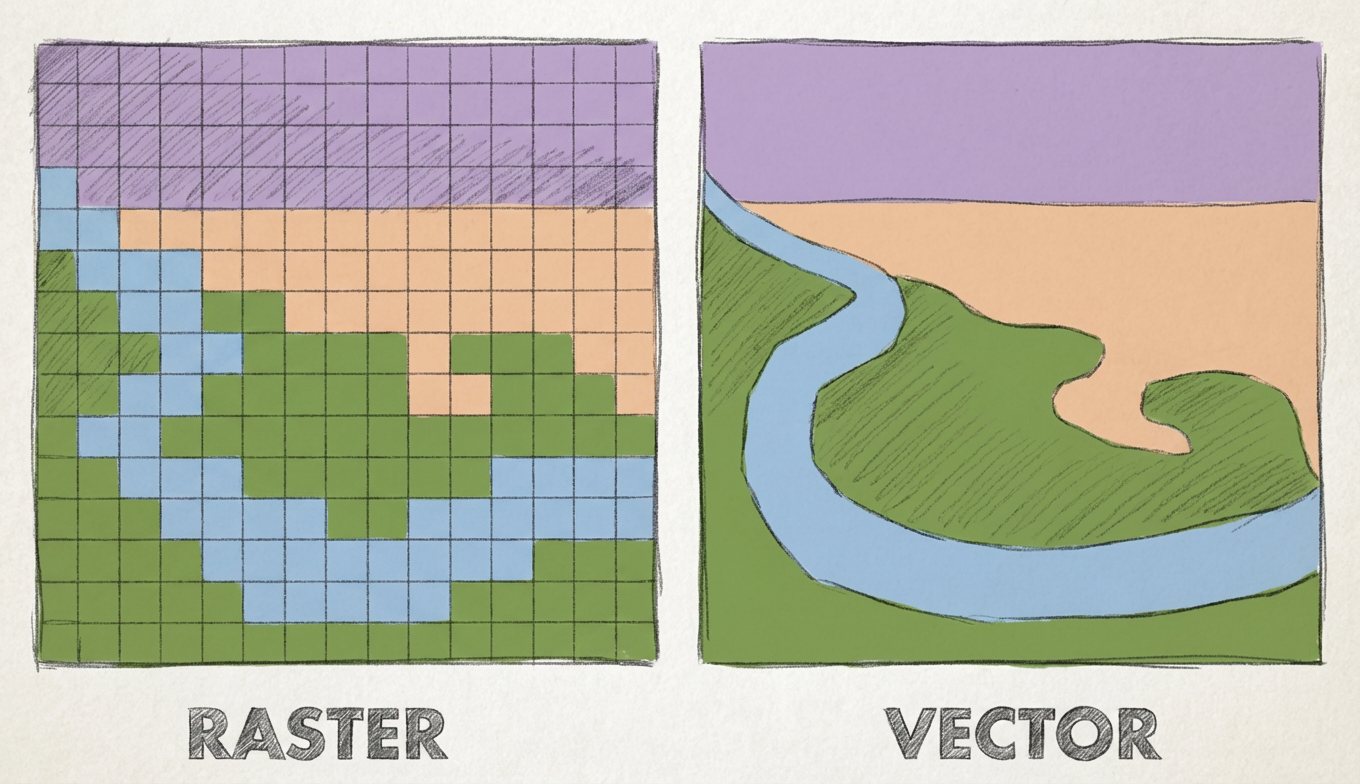


Algunas de las bibliotecas que más se usan para trabajar con datos tipo ráster son las siguientes:

- **Rasterio**: Permite la lectura, escritura y manipulación de datos ráster en formatos como GeoTIFF. Facilita la extracción de metadatos y la conversión de coordenadas espaciales.  

- **Rioarray**: Extiende rasterio para trabajar con datos ráster como arreglos de NumPy o Xarray, facilitando análisis matriciales y operaciones en múltiples bandas.  

- **EarthPy**: Proporciona herramientas para manipulación y visualización de datos geoespaciales, incluyendo funciones para procesar imágenes satelitales y generar mapas con Matplotlib.

## <font color="brown"> **¿Qué es Rasterio y para qué sirve?**

`Rasterio` (sobre GDAL) permite trabajar con **datos ráster geoespaciales** (GeoTIFF, COG, etc.) como si fueran **arreglos NumPy** con georreferenciación (CRS, tamaño de píxel, transformada) (<https://rasterio.readthedocs.io/en/latest/#>). Con Rasterio puedes:

- **Leer** bandas completas o **ventanas** (subconjuntos) sin cargar todo el archivo.
- Consultar y cambiar **CRS**, **resolución** y **extensión espacial**.
- **Recortar** por bounding box, **reproyectar** y **exportar** resultados.

Con **Rasterio**, cada ráster se trata como:
- una **matriz NumPy** (los píxeles y sus valores), y
- un **conjunto de metadatos geoespaciales** (CRS, resolución, transformada, nodata).

Esta combinación permite leer solo lo necesario (bandas específicas o subventanas), inspeccionar la georreferenciación y preparar el dato para análisis cuantitativos y mapas reproducibles.

*¿Para qué le sirve a un/a geocientífico/a?*  
- **Sensores remotos**: abrir mosaicos satelitales (Landsat, Sentinel), calcular índices espectrales (NDVI, NDSI), componer RGB/false color.  
- **Superficie y relieve**: leer DEMs, derivar pendiente, orientación y curvatura; extraer perfiles topográficos.  
- **Hidrología**: recortes por cuenca, enmascarar cuerpos de agua, reamostrar a resoluciones homogéneas.  
- **Clima**: productos ráster (precipitación, temperatura, sequía) → estadísticas por región (mean/percentiles por polígono).  
- **Cambio espacial**: comparar escenas multitemporales (antes/después), detectar anomalías y generar mapas temáticos.

En resumen: **Rasterio** es la puerta de entrada para **leer**, **recortar**, **reproyectar** y **exportar** rásteres de forma confiable, apoyándose en NumPy para el cálculo y en Matplotlib/GeoPandas para visualizar y cruzar con capas vectoriales.

**Dónde encontrar GeoTIFF abiertos**
- **USGS EarthExplorer** – escenas Landsat, SRTM, múltiples colecciones.  
  https://earthexplorer.usgs.gov/
- **Copernicus Open Access Hub / Data Space** – Sentinel-1/2/3/5P.  
  https://dataspace.copernicus.eu/
- **NASA Earthdata** (LP DAAC, GES DISC) – MODIS, VIIRS, climatología.  
  https://earthdata.nasa.gov/
- **AWS Open Data** (COGs listos para streaming: Landsat, Sentinel-2, DEMs).  
  https://registry.opendata.aws/
- **Microsoft Planetary Computer** (STAC + COG, catálogos curados).  
  https://planetarycomputer.microsoft.com/catalog
- **OpenTopography** (DEMs y derivados).  
  https://opentopography.org/
- **WorldClim / CHELSA** (clima global en GeoTIFF).  
  https://www.worldclim.org/  |  https://chelsa-climate.org/
- **ESA WorldCover** (cobertura terrestre global).  
  https://worldcover2020.esa.int/

In [1]:
pip install --user rioxarray

Note: you may need to restart the kernel to use updated packages.


In [2]:
! pip install earthpy rasterio cartopy

In [2]:
import os  # Manejo de archivos y directorios

# Manipulación y visualización de datos
import numpy as np  
import xarray as xr
import matplotlib.pyplot as plt 
import seaborn as sns 

# Análisis geoespacial
import geopandas as gpd  # Manejo de datos vectoriales 
import rasterio as rio  # Lectura y escritura de datos ráster
import rioxarray as rxr  # Extensión de rasterio para usar xarray con datos ráster

# Librería EarthPy para procesamiento y visualización geoespacial
import earthpy as et  # Funciones auxiliares para análisis geoespacial
import earthpy.plot as ep  # Herramientas para visualización de datos espaciales

# Cartopy para visualización de mapas
import cartopy.crs as ccrs  
import cartopy.feature as cfeature  
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter  # Formateo de ejes geográficos


Recuerda que la característica principal de un RÁSTER es el contener información en **PÍXELES**.

Dado que los píxeles pueden contener mucha información, un raster puede ser MUY PESADO. Para facilitar y mostrarles los elementos básicos, usaremos datos pre-cargados (pero REALES) en la biblioteca de ***EarthPy***.

Los datos de [EarthPy](https://earthpy.readthedocs.io/en/latest/earthpy-data-subsets.html) incluyen múltiples ejemplos de datos tanto de tipo Ráster como Vectoriales.

Para el día de hoy usaremos datos GeoTIFF de la [inundación de colorado en 2013](https://figshare.com/articles/dataset/Earth_Analytics_Python_Colorado_Flood_Teaching_Subset/6815945). Utilizando principalmente rásters:

- DSM (Digital Surface Model)
- DTM (Digital Terrain Model)
- Hillshade (Sombra de relieve)

Existen datos tanto antes como después de la inundación.

In [4]:
import zipfile #Para extraer datos en formato zip
import os

zip_path = '/home/jovyan/Clase_20271/data/colorado-flood.zip'  # Cambia esto por la ruta real
extract_to = '/home/jovyan/Clase_20271/data/Colorado_flood/'  # Carpeta donde se extraerán los archivos

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

### Abrir las imágenes
El parámetro `masked`, es simplemente una eliminación previa desde la lectura de aquellos valores nulos de píxel, es decir, donde no exista clara evidencia de valores reales de los datos.

Ahora veamos el contenido de fondo de dicha imagen.

In [5]:
#pip install "affine==2.4.0"

In [6]:
pre_dsm = rxr.open_rasterio("/home/jovyan/Clase_20271/data/Colorado_flood/spatial/boulder-leehill-rd/pre-flood/lidar/pre_DSM.tif", masked=True)
pre_dtm = rxr.open_rasterio("/home/jovyan/Clase_20271/data/Colorado_flood/spatial/boulder-leehill-rd/pre-flood/lidar/pre_DTM.tif", masked=True)

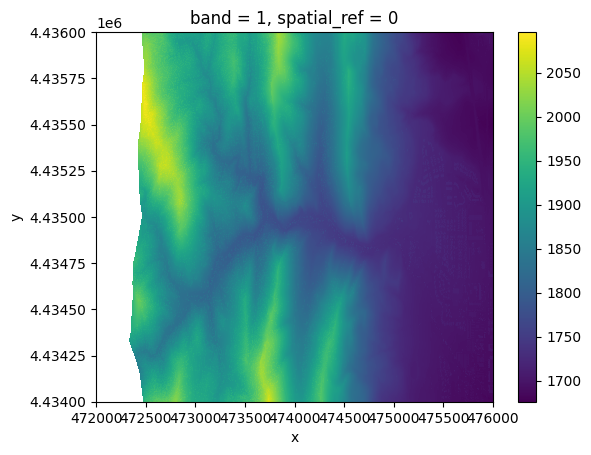

In [7]:
pre_dsm.plot()

In [8]:
pre_dsm

<xarray.DataArray (band: 1, y: 2000, x: 4000)> Size: 32MB
[8000000 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 16kB 4.436e+06 4.436e+06 ... 4.434e+06 4.434e+06
  * x            (x) float64 32kB 4.72e+05 4.72e+05 ... 4.76e+05 4.76e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

Como ves el contenido de la imagen ahora presenta un contenido numérico leído y entendido a partir de los elementos del GeoTIFF, reconociendo a una estructura de datos similar a las que hemos trabajado previamente en Python.

## <font color="darkblue"> **ELEMENTOS DEL RÁSTER**

Verifiquemos los elementos que debemos revisar previo a cualquier operación con datos de este tipo:

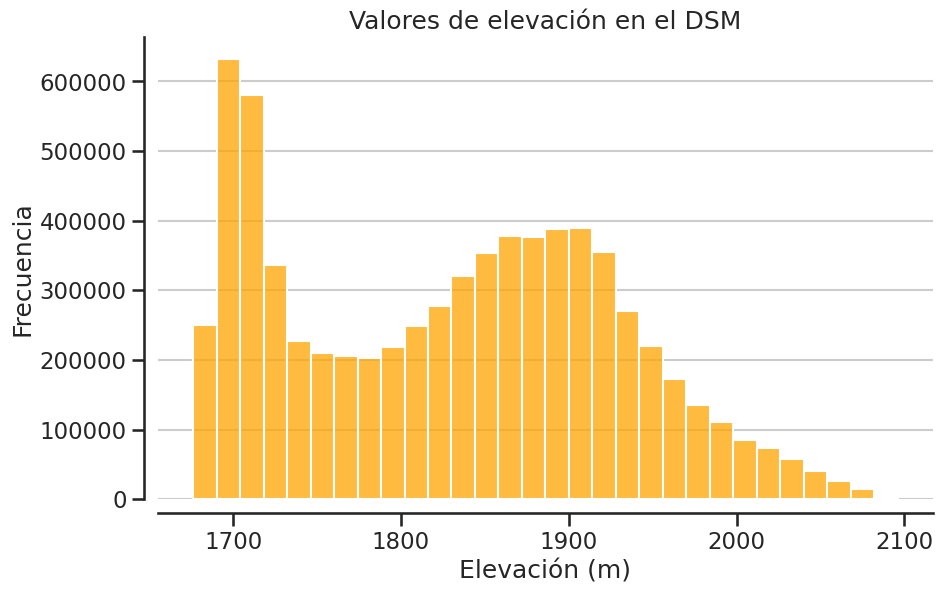

In [9]:
# Histograma

custom_params = {"axes.spines.right": True, "axes.spines.top": True, "axes.spines.left": True}
sns.set_theme(style='whitegrid', context="talk", rc=custom_params, color_codes=True)
sns.set_style("ticks")


# Crear la figura y el eje
fig, ax = plt.subplots(figsize=(10, 6))

# Graficar el histograma con Seaborn
sns.histplot(pre_dsm.values.flatten(),bins=30,color="orange",ax=ax)
sns.despine(offset=10)

# Personalizar etiquetas y título
ax.set(title="Valores de elevación en el DSM", xlabel="Elevación (m)", ylabel="Frecuencia")
ax.yaxis.grid(True)

# Mostrar la gráfica
plt.show()

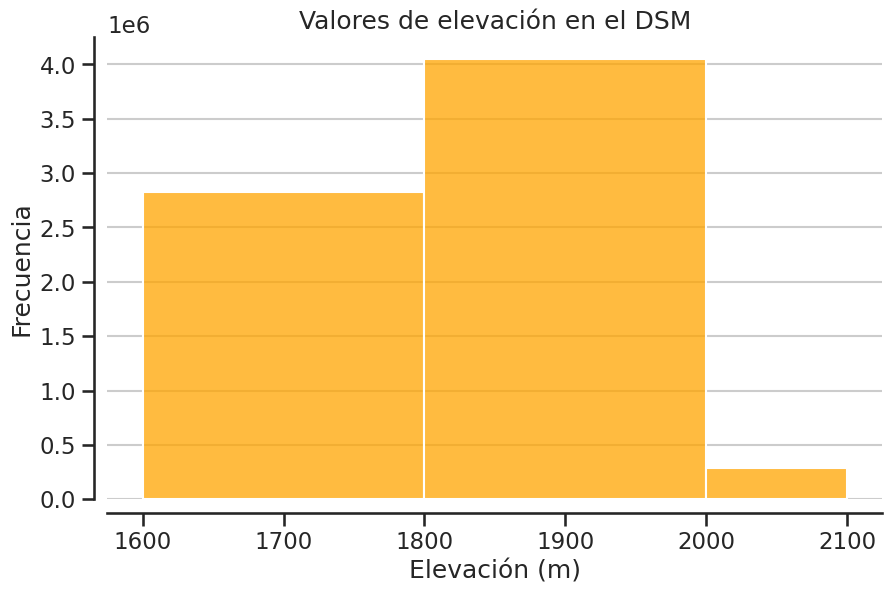

In [10]:
# Crear la figura y el eje
fig, ax = plt.subplots(figsize=(10, 6))

custom_params = {"axes.spines.right": True, "axes.spines.top": True, "axes.spines.left": True}
sns.set_theme(style='whitegrid', context="talk", rc=custom_params, color_codes=True)
sns.set_style("ticks")


# Graficar el histograma con Seaborn
sns.histplot(pre_dsm.values.flatten(),bins=[1600, 1800, 2000, 2100],color="orange",ax=ax)

# Personalizar etiquetas y título
ax.set(title="Valores de elevación en el DSM",xlabel="Elevación (m)",ylabel="Frecuencia")

sns.despine(offset=10)
ax.yaxis.grid(True)

# Mostrar la gráfica
plt.show()

El código anterior es solo mostrar los histogramas y ver el conteo de frecuencia que existe de las elevaciones.

### Ahora veamos los **metadatos**

In [11]:
print("El sistema de referencia de coordenadas (CRS) de tus datos es:", pre_dsm.rio.crs)
print("El valor de no datos (nodatavalue) de tus datos es:", pre_dsm.rio.nodata)
print("La forma (dimensiones) de tus datos es:", pre_dsm.shape)
print("La resolución espacial de tus datos es:", pre_dsm.rio.resolution())

El sistema de referencia de coordenadas (CRS) de tus datos es: EPSG:32613
El valor de no datos (nodatavalue) de tus datos es: nan
La forma (dimensiones) de tus datos es: (1, 2000, 4000)
La resolución espacial de tus datos es: (1.0, -1.0)


---
<a name='ej-1'></a>
### **<font color="DodgerBlue"> Ejercicio 1:  </font>**
<font color="DarkBlue"> 1. Con esto podemos conocer la información previa. Ahora revisa estas características **histograma y metadatos** para el DTM.

---

## <font color="brown"> **HAGAMOS ALGUNAS OPERACIONES**:

- Operaciones matemáticas con los datos de ráster (Canopy Height Model)
- Clasificación dentro del ráster y visualización

### Modelo de Altura del Copa (CHM)
El Modelo de Altura del Copa (CHM) representa la altura de los árboles. No es un valor de elevación, sino la diferencia entre el suelo y la parte superior de los árboles (o edificios, si no se han eliminado del DSM).

### Calcular la Diferencia Entre Dos Rásteres
Una forma sencilla de calcular un CHM es restando el DEM del DSM:

$DSM − DEM = CHM$


Esto nos da la diferencia entre la parte superior de la superficie terrestre y el suelo, es decir, la altura de los árboles (y edificios, si no se han limpiado los datos).

In [12]:
# ¿Los límites espaciales son los mismos?
print("¿La extensión espacial es la misma?",
      pre_dsm.rio.bounds() == pre_dtm.rio.bounds())

# ¿La resolución es la misma?
print("¿La resolución es la misma?",
      pre_dsm.rio.resolution() == pre_dtm.rio.resolution())

¿La extensión espacial es la misma? True
¿La resolución es la misma? True


In [13]:
# Calcular el Modelo de Altura del Dosel (CHM)
lidar_chm_xr = pre_dsm - pre_dtm

lidar_chm_xr

<xarray.DataArray (band: 1, y: 2000, x: 4000)> Size: 32MB
array([[[       nan,        nan,        nan, ..., 0.        ,
         0.17004395, 0.960083  ],
        [       nan,        nan,        nan, ..., 0.        ,
         0.09008789, 1.6400146 ],
        [       nan,        nan,        nan, ..., 0.        ,
         0.        , 0.07995605],
        ...,
        [       nan,        nan,        nan, ..., 0.        ,
         0.        , 0.        ],
        [       nan,        nan,        nan, ..., 0.        ,
         0.        , 0.        ],
        [       nan,        nan,        nan, ..., 0.        ,
         0.        , 0.        ]]], dtype=float32)
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 16kB 4.436e+06 4.436e+06 ... 4.434e+06 4.434e+06
  * x            (x) float64 32kB 4.72e+05 4.72e+05 ... 4.76e+05 4.76e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

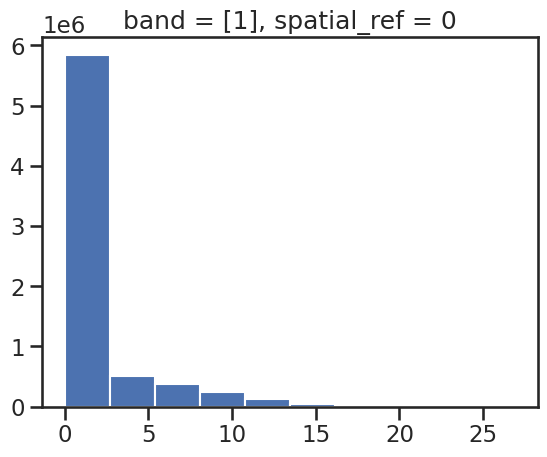

In [14]:
lidar_chm_xr.plot.hist()
plt.show()

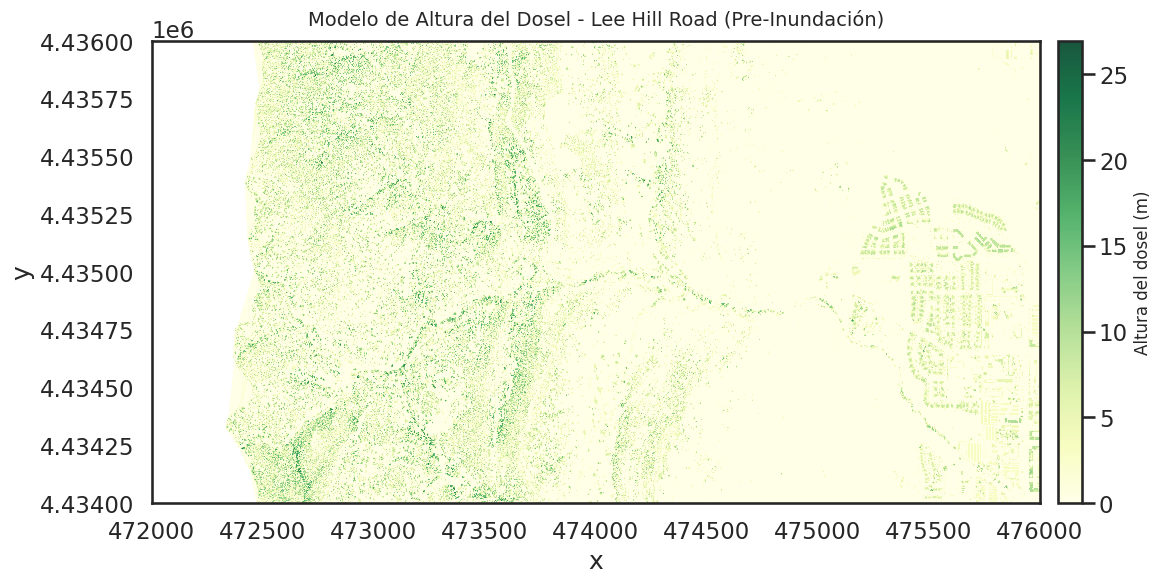

In [15]:
# Configurar estilos de visualización
sns.set_style("white")
plt.rcParams.update({"font.size": 12})

# Crear la figura y el eje
fig, ax = plt.subplots(figsize=(12, 6))

# Graficar el CHM con una mejor escala de colores y barra de color ajustada
im = lidar_chm_xr.plot(ax=ax, cmap="YlGn", alpha=0.9, add_colorbar=False)

# Agregar una barra de color personalizada
cbar = plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("Altura del dosel (m)", fontsize=12)

# Mejorar la presentación del mapa
ax.set_title("Modelo de Altura del Dosel - Lee Hill Road (Pre-Inundación)", fontsize=14, pad=12)

plt.show()

## <font color="brown"> **Clasificación dentro del ráster y visualización**

En ese ráster, cada píxel se asigna a un nuevo valor según un determinado enfoque. Este enfoque puede variar dependiendo de la pregunta científica que se quiera responder.

### **Explorar Histogramas de Ráster**  

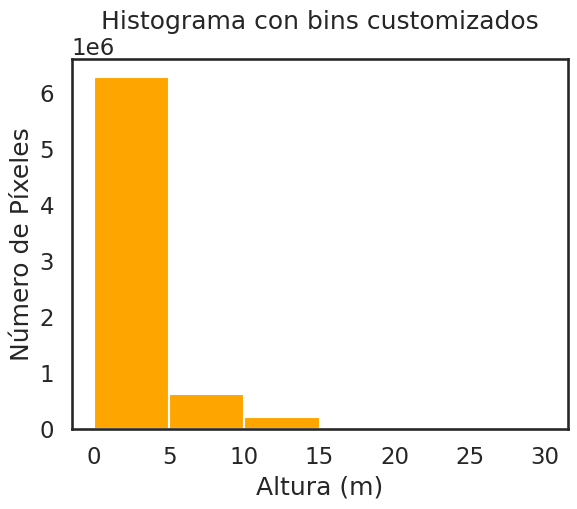

In [16]:
# Histogram with custom breaks
f, ax = plt.subplots()
lidar_chm_xr.plot.hist(color="orange",
                        bins=[0, 5, 10, 15, 20, 30])
ax.set(title="Histograma con bins customizados",
       xlabel="Altura (m)",
       ylabel="Número de Píxeles")

plt.show()

Es posible que desees ajustar la distribución de los intervalos (**bins**) del histograma. En el gráfico actual, parece que hay muchos valores cercanos a **0**.  

En el caso de este instrumento LiDAR, se sabe que los valores entre **0 y 2 metros** no son confiables (según la documentación del sensor NEON y el procesamiento de estos datos).  

### **Clasificación propuesta de altura de árboles:**  
- **0 - 2 m** → **Sin árboles** (datos no confiables)  
- **2 - 7 m** → **Árboles bajos**  
- **7 - 12 m** → **Árboles medianos**  
- **> 12 m** → **Árboles altos**  

A continuación, puedes experimentar con estos intervalos para visualizar mejor la distribución de alturas en tu dataset. 🌳

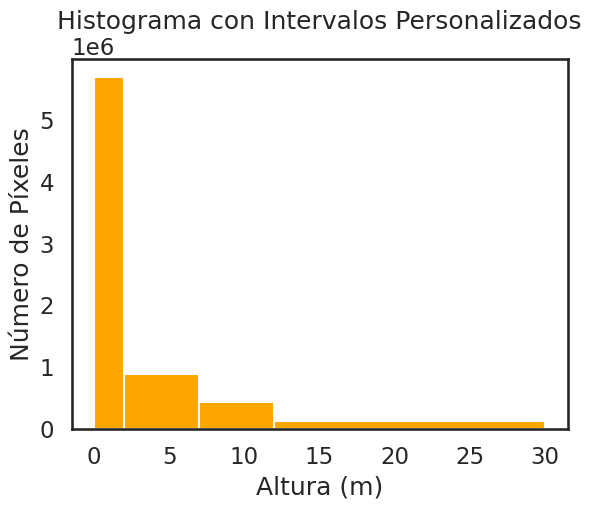

In [17]:
# Histograma con intervalos personalizados
f, ax = plt.subplots()

lidar_chm_xr.plot.hist(
    color='orange',
    bins=[0, 2, 7, 12, 30])
ax.set(title="Histograma con Intervalos Personalizados",
       xlabel="Altura (m)",
       ylabel="Número de Píxeles")

plt.show()

### <font color="brown">**Mapear los valores del ráster a nuevos valores (Reclasificación del Ráster)**  
Para reclasificar tu ráster, primero necesitas crear una **matriz de reclasificación**.  

Esta matriz **mapea** un rango de valores a un nuevo valor definido. Utilizarás esta matriz para crear un modelo de altura del dosel clasificado, donde designarás **árboles bajos**, **medios** y **altos**.  

Los nuevos valores definidos serán los siguientes:

- **Sin árboles**: (0m - 2m de altura) = **NA**  
- **Árboles bajos**: (2m - 7m de altura) = **1**  
- **Árboles medianos**: (7m - 12m de altura) = **2**  
- **Árboles altos**: (> 12m de altura) = **3**  

### **Observaciones**:  
1. En la lista anterior, configuraste las celdas con un valor entre **0 y 2 metros** como **NA** o valor **nodatavalue**. Esto significa que estás asumiendo que no hay árboles en esas ubicaciones.  
2. En la matriz de reclasificación, se utiliza **Inf** para representar el valor más grande o el valor máximo encontrado en el ráster. Entonces, la asignación sería la siguiente:

| **Rango de altura (m)** | **Valor reclasificado** |
|-------------------------|-------------------------|
| 0 - 2                   | NA (Sin árboles)        |
| 2 - 7                   | 1 (Árboles bajos)       |
| 7 - 12                  | 2 (Árboles medianos)    |
| > 12 o 12 - Inf          | 3 (Árboles altos)       |


In [18]:
lidar_chm_xr.rio.nodata

In [19]:
data_min_value = np.nanmin(lidar_chm_xr)
data_max_value = np.nanmax(lidar_chm_xr)
print(data_min_value, data_max_value)

0.0 26.930054


In [20]:
class_bins = [-np.inf, 2, 7, 12, np.inf]
class_bins

[-inf, 2, 7, 12, inf]

In [21]:
# Clasificación de datos usando xarray
pre_lidar_chm_class = xr.apply_ufunc(np.digitize,lidar_chm_xr,class_bins)

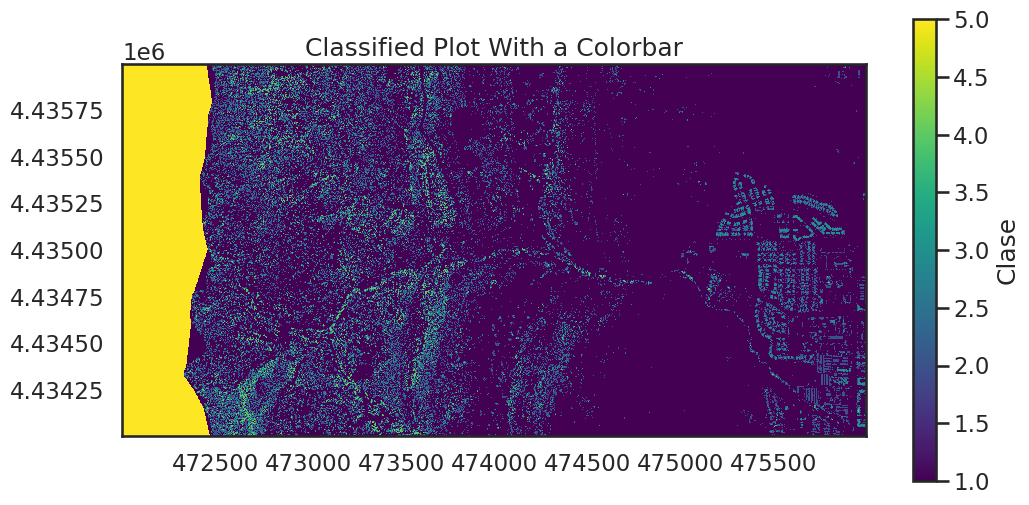

In [22]:
datos = pre_lidar_chm_class.values[0]

f, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(datos, cmap="viridis",interpolation="nearest", #Conserva los valores originales de las celdas. Cada píxel mostrado toma el valor de la celda más cercana.
               extent=[pre_lidar_chm_class["x"].min(), pre_lidar_chm_class["x"].max(), pre_lidar_chm_class["y"].min(), pre_lidar_chm_class["y"].max()]) 

f.colorbar(im, ax=ax, label="Clase")
ax.set_title("Classified Plot With a Colorbar")

plt.show()

In [23]:
# Enmasacarando valores igual 5 que representan valores nulos
pre_lidar_chm_class_ma = pre_lidar_chm_class.where(pre_lidar_chm_class != 5)
pre_lidar_chm_class_ma

<xarray.DataArray (band: 1, y: 2000, x: 4000)> Size: 64MB
array([[[nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.],
        ...,
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.],
        [nan, nan, nan, ...,  1.,  1.,  1.]]])
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 16kB 4.436e+06 4.436e+06 ... 4.434e+06 4.434e+06
  * x            (x) float64 32kB 4.72e+05 4.72e+05 ... 4.76e+05 4.76e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

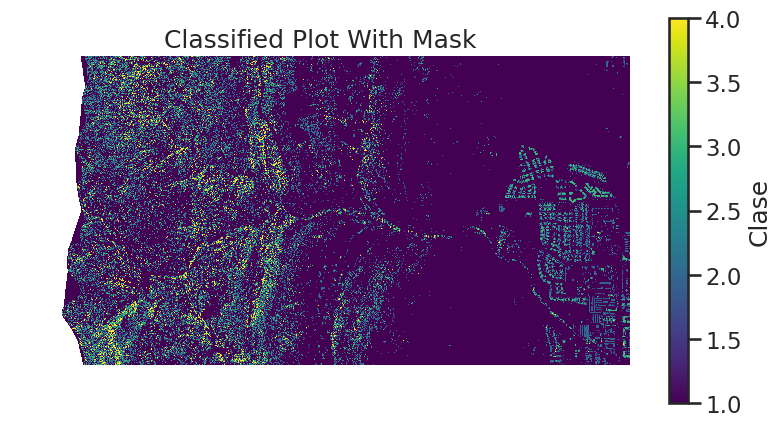

In [24]:
datos = pre_lidar_chm_class_ma.values[0]

f, ax = plt.subplots(figsize=(10, 5))

im = ax.imshow(datos, cmap="viridis",interpolation="nearest",
              extent=[pre_lidar_chm_class_ma["x"].min(), pre_lidar_chm_class_ma["x"].max(), pre_lidar_chm_class_ma["y"].min(), pre_lidar_chm_class_ma["y"].max()])
f.colorbar(im, ax=ax, label="Clase")

ax.set_title("Classified Plot With Mask")
ax.set_axis_off()

plt.show()

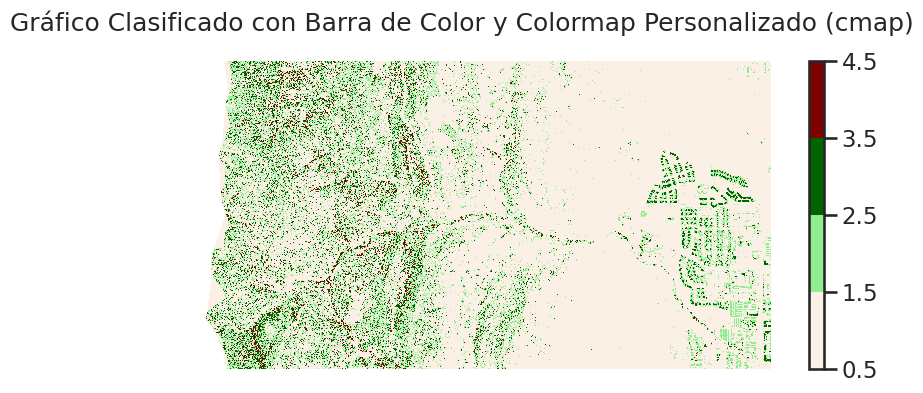

In [29]:
from matplotlib.colors import ListedColormap, BoundaryNorm

## Graficar los datos usando colores más agradables
colors = ['linen', 'lightgreen', 'darkgreen', 'maroon']
class_bins = [0.5, 1.5, 2.5, 3.5, 4.5]

cmap = ListedColormap(colors)
norm = BoundaryNorm(class_bins, len(colors))


# Graficar con imshow el ráster recién clasificado y enmascarado
fig, ax = plt.subplots(figsize=(10, 4))

im = ax.imshow(pre_lidar_chm_class_ma.values[0],cmap=cmap,norm=norm,interpolation="nearest",
               extent=[pre_lidar_chm_class_ma["x"].min(), pre_lidar_chm_class_ma["x"].max(), pre_lidar_chm_class_ma["y"].min(), pre_lidar_chm_class_ma["y"].max()])

fig.colorbar(im,ax=ax)

ax.set(title="Gráfico Clasificado con Barra de Color y Colormap Personalizado (cmap)")
ax.set_axis_off()
plt.show()

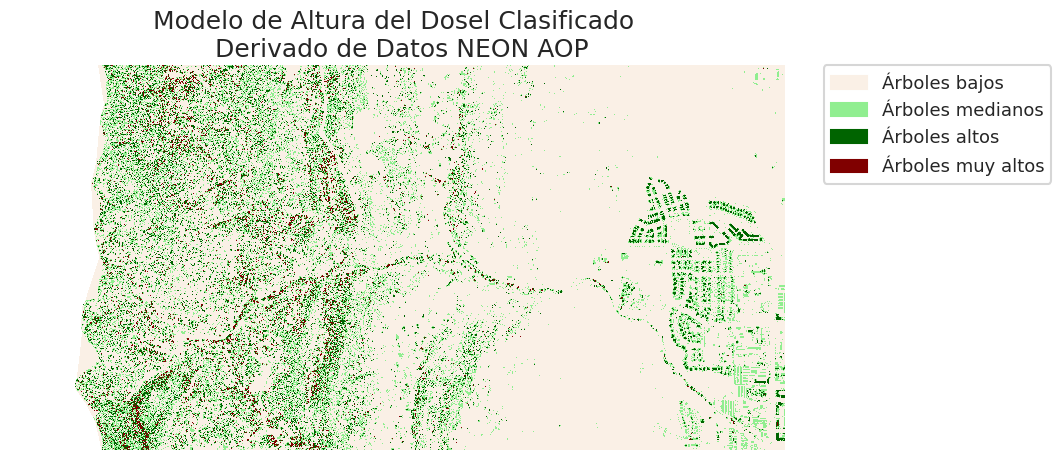

In [30]:
# Crear una lista de etiquetas para la leyenda
etiquetas_altura = ["Árboles bajos",
                    "Árboles medianos",
                    "Árboles altos",
                    "Árboles muy altos"]

# Crear un colormap a partir de una lista de colores
colores = ['linen', 'lightgreen', 'darkgreen', 'maroon']
cmap = ListedColormap(colores)

# Definir los límites de las clases para la reclasificación
class_bins = [.5, 1.5, 2.5, 3.5, 4.5]
norm = BoundaryNorm(class_bins, len(colores))

# Graficar el ráster recién clasificado y enmascarado
f, ax = plt.subplots(figsize=(10, 5))

# Imágenes del ráster
im = pre_lidar_chm_class_ma.squeeze().plot.imshow(cmap=cmap, norm=norm, add_colorbar=False)

# Asegurarse de que la imagen esté correctamente renderizada
ax.set(title="Modelo de Altura del Dosel Clasificado \n Derivado de Datos NEON AOP")
ax.set_axis_off()

# Agregar la leyenda utilizando EarthPy
# Ahora pasamos el objeto de imagen correctamente a draw_legend
ep.draw_legend(im, titles=etiquetas_altura)

# Mostrar la gráfica
plt.show()


In [42]:
pre_lidar_chm_class_ma.rio.to_raster("dosel_mask.tif") #Gudardar rástaer a partir de un DataArray

---
<a name='ej-1'></a>
### **<font color="DodgerBlue"> Ejercicio 2: Replica el análisis que hicimos ahora con los datos post-inundación  </font>**
<font color="DarkBlue"> 1. Carga y grafica los archivos DSM y DTM.

<font color="DarkBlue"> 2. Obtenén los histogramas de DSM y DTM post inundación

<font color="DarkBlue"> 3. Obtén el Modelo de Altura del Copa (CHM) post inundación.

¿Hubo alguna diferencia?



# <font color="brown"> **Uniendo bandas**

En el análisis de datos geoespaciales, cada banda de un ráster representa una capa de información espacial, como la elevación del terreno, la temperatura, la precipitación o la reflectancia de una superficie. **La unión de bandas** consiste en combinar dos o más capas ráster en un solo archivo multibanda, de manera que cada banda conserve su información y pueda analizarse junto con las demás.

Esta operación es útil cuando queremos integrar diferentes variables de una misma región geográfica para facilitar su visualización, comparación y análisis conjunto.

In [32]:
# 1) Abrir el GeoTIFF (RGB) desde una URL pública
url_tif = "https://raw.githubusercontent.com/rasterio/rasterio/main/tests/data/RGB.byte.tif"
with rio.open(url_tif) as src:
    # 2) Inspeccionar metadatos principales
    print("CRS:", src.crs)
    print("Bandas:", src.count)
    print("Tamaño (ancho, alto):", (src.width, src.height))

    # 3) Leer las 3 bandas (R,G,B) como arreglos 2D (alto x ancho)
    r = src.read(1)  # banda 1 = rojo
    g = src.read(2)  # banda 2 = verde
    b = src.read(3)  # banda 3 = azul

CRS: EPSG:32618
Bandas: 3
Tamaño (ancho, alto): (791, 718)


--------------------
Hasta este punto, las bandas roja, verde y azul están guardadas en tres arreglos independientes. Ahora vamos a combinarlas para crear una imagen.

In [33]:
# 4) Construir un arreglo RGB (alto x ancho x 3)
rgb = np.dstack([r, g, b]).astype("float32")

# 5) Normalizar a 0–1 para mostrar (si ya estuviera en 0–255, no hace falta)
rgb_min = rgb.min()
rgb_max = rgb.max()
rgb = (rgb - rgb_min) / (rgb_max - rgb_min + 1e-9)

(np.float64(-0.5), np.float64(790.5), np.float64(717.5), np.float64(-0.5))

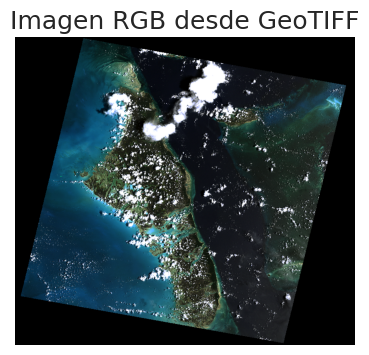

In [34]:
# 6) Visualizar
plt.figure(figsize=(5,4))
plt.imshow(rgb)
plt.title("Imagen RGB desde GeoTIFF")
plt.axis("off") #Oculta los ejes, las marcas y sus etiquetas.

In [35]:
from rasterio.windows import from_bounds

### Lectura por “ventana” con Rasterio: qué es y por qué sirve

Un ráster es una **rejilla de píxeles** posicionada en la Tierra mediante una transformación afín (el `transform`) y un **CRS**.  
A veces no queremos leer la imagen completa (por tamaño o velocidad), sino solo un rectángulo del raster: a eso Rasterio le llama una **ventana**.

En la siguiente celda se:
1) Inspecciona el ráster para conocer su **extensión espacial** (`bounds`) y su **transform**.  
2) Elije un **bounding box** (minx, miny, maxx, maxy) **dentro de** `bounds`.  
3) Con `from_bounds(...)` convierte ese bbox (en coordenadas del mapa) a una *ventana de píxeles* (filas/columnas).  
4) Lee *solo esa ventana* con `src.read(window=win)`.  
5) Si quiero guardar el recorte, debo actualizar `width`, `height` y el nuevo `transform` que describe la georreferenciación del recorte.

Ventaja: ahorro memoria/tiempo y trabajo exactamente en la zona de interés, manteniendo la georreferenciación correcta.

In [36]:
with rio.open(url_tif) as src:
    # Imprime el CRS (sistema de referencia), útil para saber en qué unidades/coords está el ráster
    print("CRS:", src.crs)
    # Imprime la extensión espacial: (minx, miny, maxx, maxy)
    print("Bounds:", src.bounds)
    # Imprime la transformación afín: mapea pixeles (fila, col) ↔ coords del mapa (x, y)
    print("Transform:", src.transform)

    # Desempaqueta la extensión para construir un bbox centrado y más pequeño
    minx, miny, maxx, maxy = src.bounds
    
    # Centro del ráster
    cx = (minx + maxx) / 2.0
    cy = (miny + maxy) / 2.0
    
    # Tamaño del recorte (30% de la anchura/altura del ráster)
    dx = (maxx - minx) * 0.15
    dy = (maxy - miny) * 0.15
    
    # Bounding box elegido (en las mismas coordenadas que el ráster)
    bbox = (cx - dx, cy - dy, cx + dx, cy + dy)
    print("BBox elegido:", bbox)

    # Convierte el bbox (coords del mapa) a una ventana (en píxeles), usando el transform del dataset
    win = from_bounds(*bbox, transform=src.transform)
    
    # Muestra la ventana resultante: (desplazamiento de columna, desplazamiento de fila, ancho, alto)
    print("Ventana (col_off, row_off, width, height):", (win.col_off, win.row_off, win.width, win.height))

    # Lee solo esa ventana. 'data' tiene forma (bandas, filas, columnas)
    data = src.read(window=win)

CRS: EPSG:32618
Bounds: BoundingBox(left=101985.0, bottom=2611485.0, right=339315.0, top=2826915.0)
Transform: | 300.04, 0.00, 101985.00|
| 0.00,-300.04, 2826915.00|
| 0.00, 0.00, 1.00|
BBox elegido: (185050.5, 2686885.5, 256249.5, 2751514.5)
Ventana (col_off, row_off, width, height): (np.float64(276.8500000000001), np.float64(251.29999999999927), np.float64(237.3), np.float64(215.39999999999964))


(np.float64(-0.5), np.float64(236.5), np.float64(214.5), np.float64(-0.5))

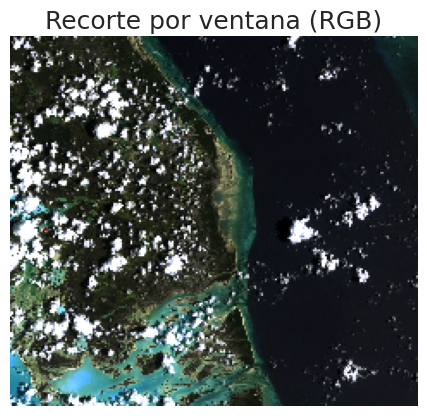

In [37]:
# Apila las tres primeras bandas como imagen RGB
rgb = np.dstack([data[0], data[1], data[2]]).astype("float32")
# Normaliza a 0–1 para visualizar
rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-9)
plt.imshow(rgb)
plt.title("Recorte por ventana (RGB)")
plt.axis("off")